# Pipeline: stationarity → ARMA → ARMA–GARCH

**Question.** How should one build a conditional model for daily equity market excess returns — starting from integration properties, then a constant-variance mean, then volatility clustering?

**Data.** Fama–French **Mkt–RF** daily excess returns (`exemples/ARMA_GARCH/data/ff_mkt_rf_daily.csv`), subsample **2015-01-02 → 2023-12-29** (~2 260 observations). The subsample keeps computation light while covering several volatility regimes (including 2020).

**Why this order of steps.**

1. **Stationarity** — returns are modeled as (weakly) stationary processes. If levels of a price series were used by mistake, ARMA/GARCH would be mis-specified; unit-root checks document that we are in the return domain.
2. **ARMA with constant variance** — establishes the **conditional mean** and shows what fails (non-normality, ARCH in residuals). Jumping straight to GARCH without a mean reference model hides whether dynamics come from the mean or the variance.
3. **ARMA–GARCH** — addresses volatility clustering and fat tails once the mean is disciplined. Student-t innovations are introduced only after Gaussian GARCH is shown to leave residual non-normality.

This is the classical empirical sequence in applied financial econometrics, not a software demo of random features.

Requires **makystats ≥ 0.1.5**.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from makystats import adf, adf_sequential, kpss, arma, arma_garch

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.titlesize"] = 12

## 2. Data

`MktRF` is the value-weighted market excess return in **percent per day**. We work with returns, not log prices.


In [5]:
df = pd.read_csv("../ARMA_GARCH/data/ff_mkt_rf_daily.csv", parse_dates=["date"])
df = df.set_index("date").sort_index()
r = df.loc["2015-01-01":"2023-12-31", "MktRF"].astype(float)

print(f"Sample: {r.index.min().date()} → {r.index.max().date()}  (n = {len(r)})")
print(r.describe().round(4))

Sample: 2015-01-02 → 2023-12-29  (n = 2264)
count    2264.0000
mean        0.0456
std         1.1804
min       -12.0100
25%        -0.4100
50%         0.0500
75%         0.6125
max         9.3400
Name: MktRF, dtype: float64


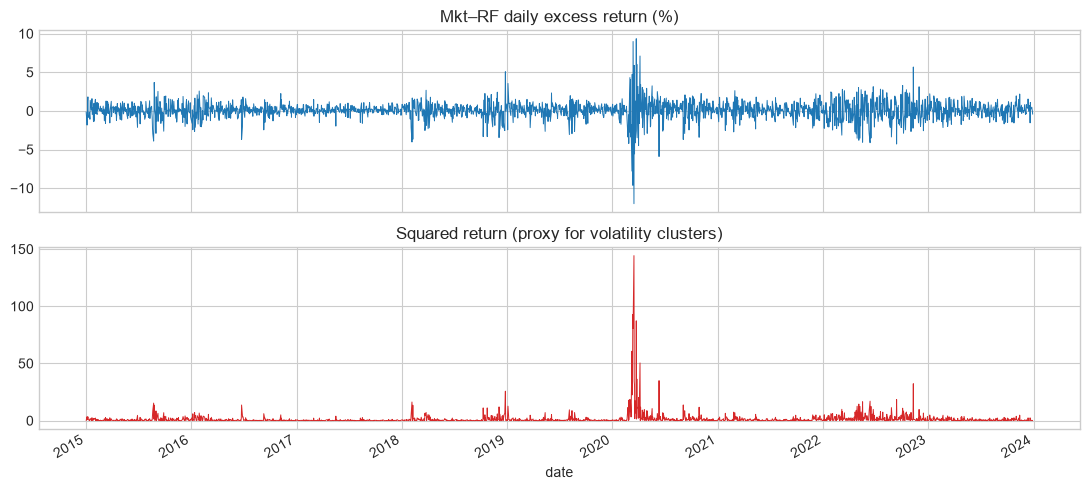

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
r.plot(ax=axes[0], title="Mkt–RF daily excess return (%)", color="C0", legend=False, lw=0.7)
(r**2).plot(ax=axes[1], title="Squared return (proxy for volatility clusters)", color="C3", legend=False, lw=0.7)
fig.tight_layout()
plt.show()

Squared returns already suggest **volatility clustering**: quiet periods and stormy periods alternate. That visual is a motivation for GARCH *later*; first we confirm stationarity and fit a mean model.


## 3. Stationarity of excess returns

Daily excess returns should behave as **I(0)** (mean-reverting in the weak-stationary sense). We use the sequential ADF strategy plus KPSS for a cross-check.


Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 9
  nobs       : 2254
  final model: c
  conclusion : I(0) with non-zero mean
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -14.9567
        pvalue: 2.29928e-22
        reject_unit_root: True
        coef_trend: -8.70837e-07
        t_trend: -0.0235757
        coef_const: 0.0515492
        t_const: 1.06975
    (2) Model 3: unit root rejected — Student test trend b = 0
        t_trend: -0.0235757
        pvalue_trend_approx: 0.981193
        trend_significant: False
        note: Under stationarity, Student-t approximation for b.
    (3) Model 3: trend not significant — continue to Model 2
        reason: Testing unit root in a trend model was not warranted
    (4) Model 2 (const): test H0: rho = 0
        t_rho: -14.9602
        pvalue: 1.24291e-27
        reject_unit_root: True
        coef_const: 0.0505676
        t_const: 2.0848
    (5) Model 2: unit root rejected — Student test con

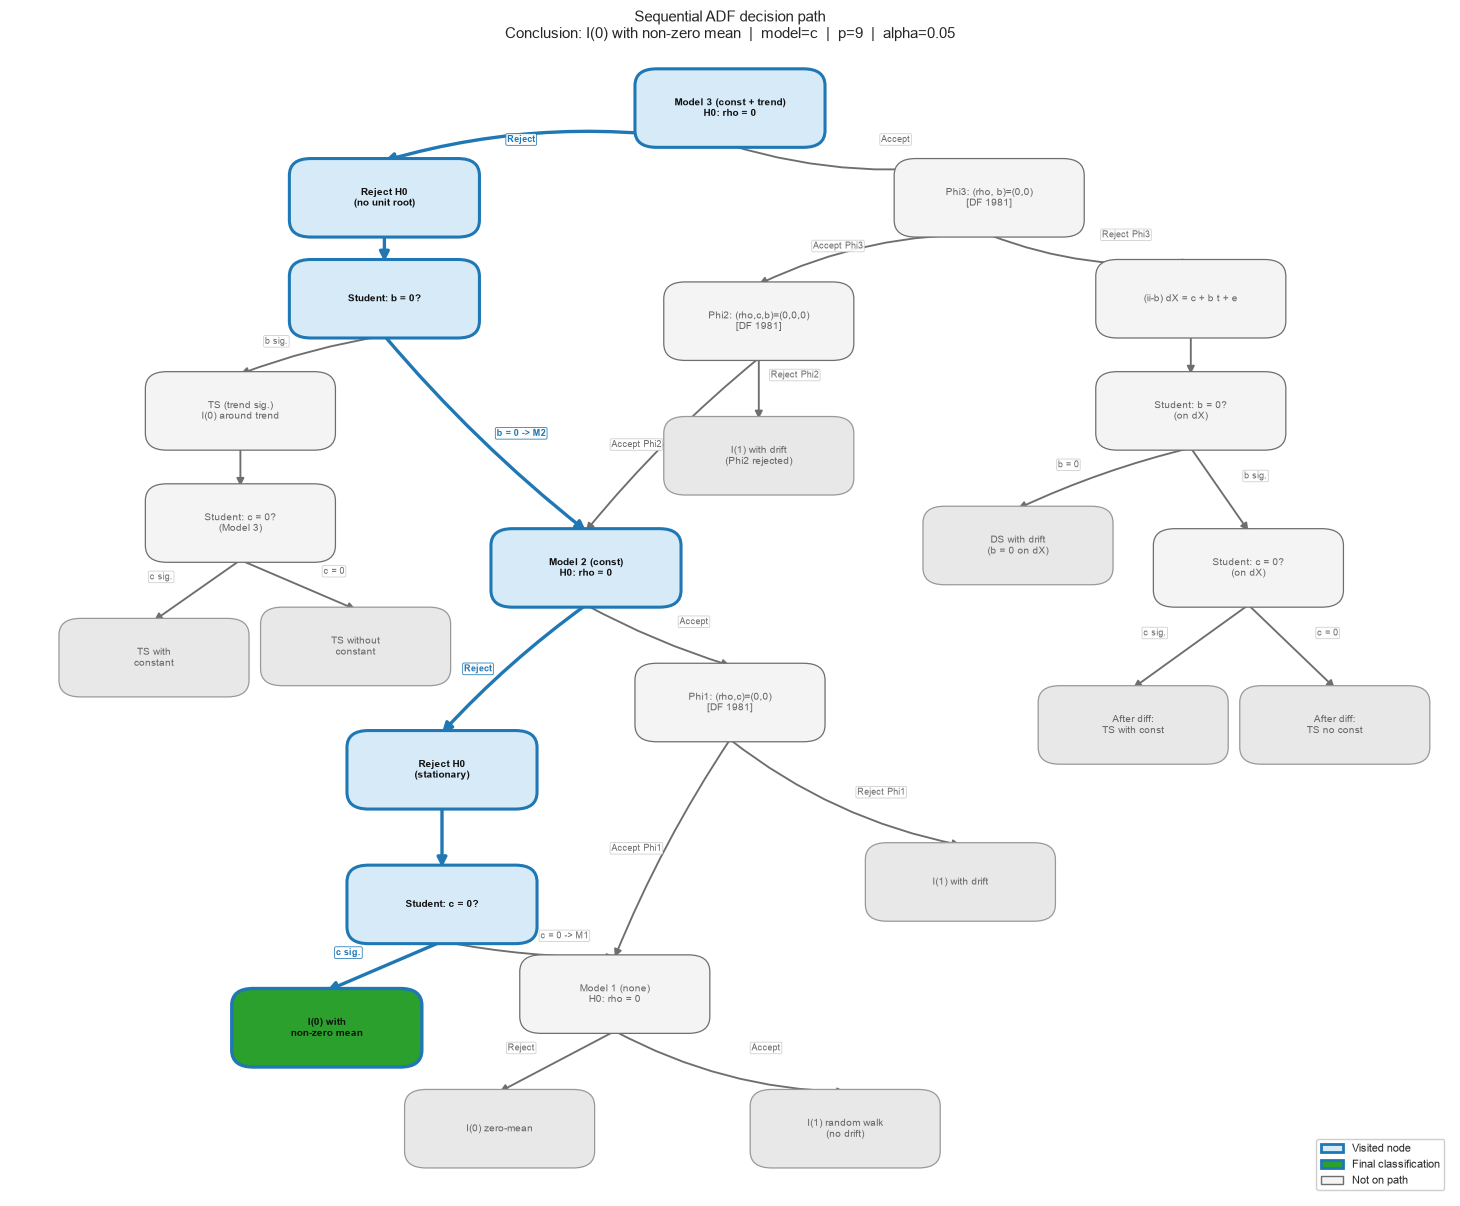

In [9]:
seq = adf_sequential(r, alpha=0.05)
print(seq.summary())
print()
k = kpss(r, regression="c")
print(f"KPSS (null: level-stationary): stat={k.statistic:.4f}, p≈{k.pvalue:.4g}")
print(f"Sample mean = {r.mean():.4f}%,  std = {r.std():.4f}%")
seq.plot()
plt.show()

### Interpretation

The sequential ADF path almost always **rejects the unit root** already in Model 3 and lands on **I(0) with a non-zero mean** (equity premium in the sample mean). KPSS typically **fails to reject** stationarity for returns.

**Modeling implication:** no differencing (`d = 0`). An ARMA in levels of *returns* is appropriate. (Differencing returns would over-difference and induce an MA unit root.)


## 4. Constant-variance ARMA mean

### Why AR(1) as the baseline?

Empirically, daily index excess returns show **weak short-run autocorrelation** (often a small negative AR(1) at daily frequency with liquid indices — microstructure / bounce effects and mild mean dynamics). We start with **AR(1) + constant**:

- parsimonious;
- nests white noise (AR coefficient = 0);
- leaves clear residual diagnostics for heteroskedasticity.

A full `select_arma_order` grid is possible; on ~2 000 daily points many \((p,q)\) are similar. The scientific point of this pipeline is the **mean → variance** progression, not an exhaustive order search. We still compare AR(1) to white noise and ARMA(1,1) briefly via BIC after estimation.


                                 ARMA Results                                 
Dep. Variable:                   MktRF   No. Observations:             2263
Model:                       ARMA(1,0)   Log Likelihood:          -3566.218
Date:                 Wed, 04 Nov 2026   AIC:                      7138.436
Time:                         18:11:42   BIC:                      7155.609
Sample:                     2015-01-02   HQIC:                     7144.702
                          - 2023-12-29                                     
Covariance Type:                   opg                                     
                      coef   std err         z     P>|z|    [0.025    0.975]
------------------------------------------------------------------------------
const               0.0457    0.0225    2.0349     0.042    0.0017    0.0897
ar.L1              -0.1329    0.0085  -15.6194     0.000   -0.1495   -0.1162
sigma2              1.3687    0.0171   80.1661     0.000    1.3353    1.4022
Lj

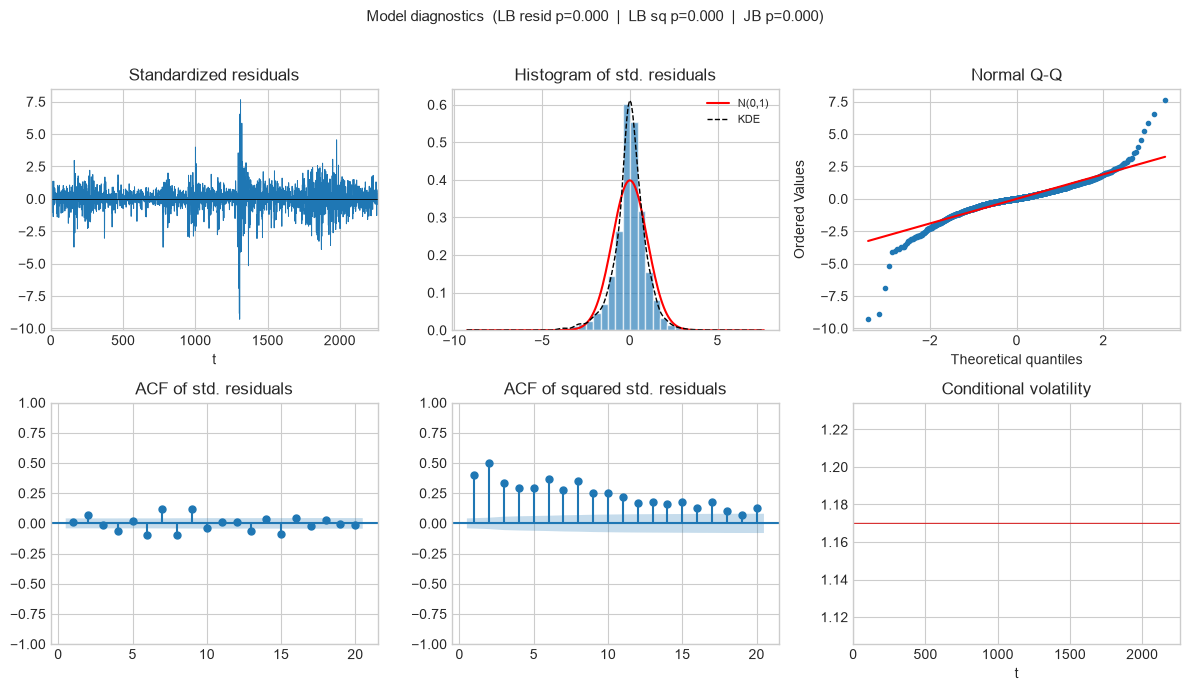

In [14]:
# Constant-variance Gaussian AR(1)
mean_ar1 = arma(r, mean="AR", ar=1, ma=0, d=0, trend="c", dist="normal").fit(verbose=False)
print(mean_ar1.summary())
mean_ar1.plot_diagnostics()
plt.show()

In [15]:
# Reference models for IC comparison
mean_wn = arma(r, mean="Constant", ar=0, ma=0, d=0, trend="c", dist="normal").fit(verbose=False)
mean_arma11 = arma(r, mean="ARMA", ar=1, ma=1, d=0, trend="c", dist="normal").fit(verbose=False)

ic = pd.DataFrame({
    "AIC": [mean_wn.aic, mean_ar1.aic, mean_arma11.aic],
    "BIC": [mean_wn.bic, mean_ar1.bic, mean_arma11.bic],
}, index=["WN + const", "AR(1)", "ARMA(1,1)"])
print(ic.round(2))
print()
print("AR(1) preferred over WN on BIC?" , mean_ar1.bic < mean_wn.bic)

                AIC      BIC
WN + const  7178.93  7190.38
AR(1)       7138.44  7155.61
ARMA(1,1)   7180.62  7203.52

AR(1) preferred over WN on BIC? True


### What the constant-variance AR(1) reveals

From a typical fit on this sample:

- **AR(1) coefficient** is small but statistically significant; BIC usually prefers AR(1) to pure white noise.
- **Ljung–Box on residuals** at short lags is often acceptable (linear mean dynamics largely captured).
- **Jarque–Bera** rejects normality harshly (excess kurtosis).
- High kurtosis + the squared-return plot point to **conditional heteroskedasticity**, not to more ARMA lags as the main missing feature.

Adding ARMA lags cannot fix volatility clustering: the next step is a **variance equation**.


## 5. ARMA–GARCH: joint mean and variance

We keep the **AR(1) mean** and add **GARCH(1,1)**, the workhorse volatility model:

\[
\begin{aligned}
r_t &= \mu + \phi r_{t-1} + \varepsilon_t, \\
\varepsilon_t &= \sigma_t z_t, \\
\sigma_t^2 &= \omega + \alpha \varepsilon_{t-1}^2 + \beta \sigma_{t-1}^2.
\end{aligned}
\]

**Why (1,1)?** For daily equity indices, GARCH(1,1) captures the bulk of clustering; higher orders rarely improve out-of-sample fit once (1,1) is allowed. Persistence \(\alpha+\beta\) close to one is expected (slow decay of variance shocks).

Estimation is **joint MLE** (mean and variance together), which is the point of `arma_garch` in makystats.



   ARMA(1,0) - GARCH(1,1) — MLE (MLE)
   Mean: AR  |  trend=c  |  Distribution: NORMAL  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : -3009.073889
AIC            : 6028.1478
BIC            : 6056.7700
Sample (adjusted) : 2 2264  (burn-in = 1)
Observations   : 2263
Paramètres     : 5

--- Coefficients (IC 95% dans self.coef_table) ---
             Coeff   Std.Err     z-Stat     Prob.  CI_low_95  CI_high_95
const     0.083574  0.014836   5.633177  0.000000   0.054496    0.112652
AR(1)    -0.063961  0.023144  -2.763635  0.005716  -0.109322   -0.018600
omega     0.039260  0.004440   8.842956  0.000000   0.030558    0.047962
alpha(1)  0.189414  0.015633  12.116094  0.000000   0.158774    0.220055
beta(1)   0.784151  0.016107  48.682606  0.000000   0.752581    0.815720

--- Diagnostic ---
alpha+beta = 0.973565
Ljung-Box (10) sur résidus std : p-val = 0.5880
Ljung-Box (10) sur carrés std  : p-val = 0.5147
Jarque-Bera (normali

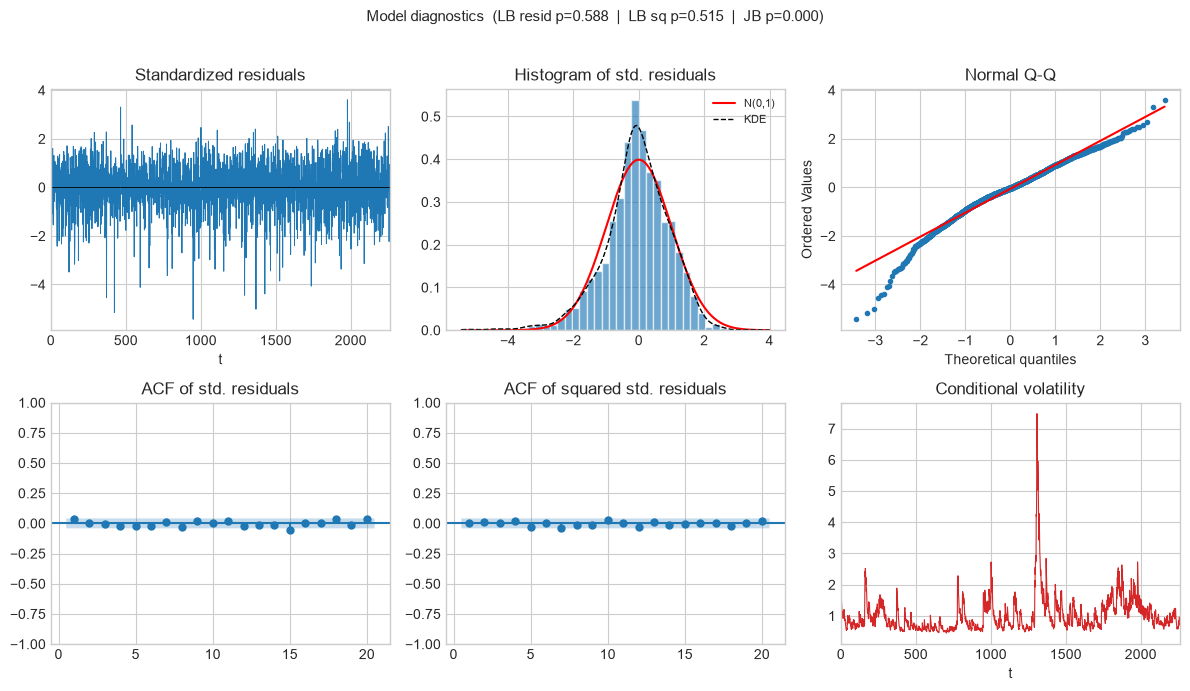

In [18]:
garch_n = arma_garch(
    r,
    mean="AR", ar=1, ma=0, d=0,
    r=1, s=1,          # GARCH(1,1): ARCH order r, GARCH order s
    trend="c",
    dist="normal",
).fit(verbose=False)
print(garch_n.summary())
garch_n.plot_diagnostics()
plt.show()

### Gaussian GARCH — reading the diagnostics

- **Log-likelihood** jumps relative to constant-variance AR(1): variance dynamics were first-order important.
- \(\alpha+\beta\) near 1: highly persistent volatility (still stationary if \(< 1\)).
- **Ljung–Box on standardised residuals and their squares** should improve versus the constant-variance model if GARCH is well specified.
- **Jarque–Bera on standardised residuals** often still rejects: Gaussian innovations understate tail thickness. That motivates Student-t innovations — not a different mean lag structure.


## 6. Student-t innovations

Replace \(z_t \sim N(0,1)\) with standardised **Student-t** (degrees of freedom \(\nu\) estimated). This is the usual next step when standardised residuals remain leptokurtic under normality.



   ARMA(1,0) - GARCH(1,1) — MLE (MLE)
   Mean: AR  |  trend=c  |  Distribution: T  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : -2949.866179
AIC            : 5911.7324
BIC            : 5946.0790
Sample (adjusted) : 2 2264  (burn-in = 1)
Observations   : 2263
Paramètres     : 6

--- Coefficients (IC 95% dans self.coef_table) ---
             Coeff   Std.Err     z-Stat     Prob.  CI_low_95  CI_high_95
const     0.094636  0.014482   6.534760  0.000000   0.066252    0.123020
AR(1)    -0.052636  0.022689  -2.319923  0.020345  -0.097105   -0.008167
omega     0.020807  0.005402   3.851734  0.000117   0.010220    0.031395
alpha(1)  0.168196  0.021371   7.870153  0.000000   0.126309    0.210083
beta(1)   0.827208  0.019679  42.034734  0.000000   0.788638    0.865779
nu        6.205466  0.759834   8.166866  0.000000   4.716218    7.694714

--- Diagnostic ---
alpha+beta = 0.995404
Ljung-Box (10) sur résidus std : p-val = 0.7143


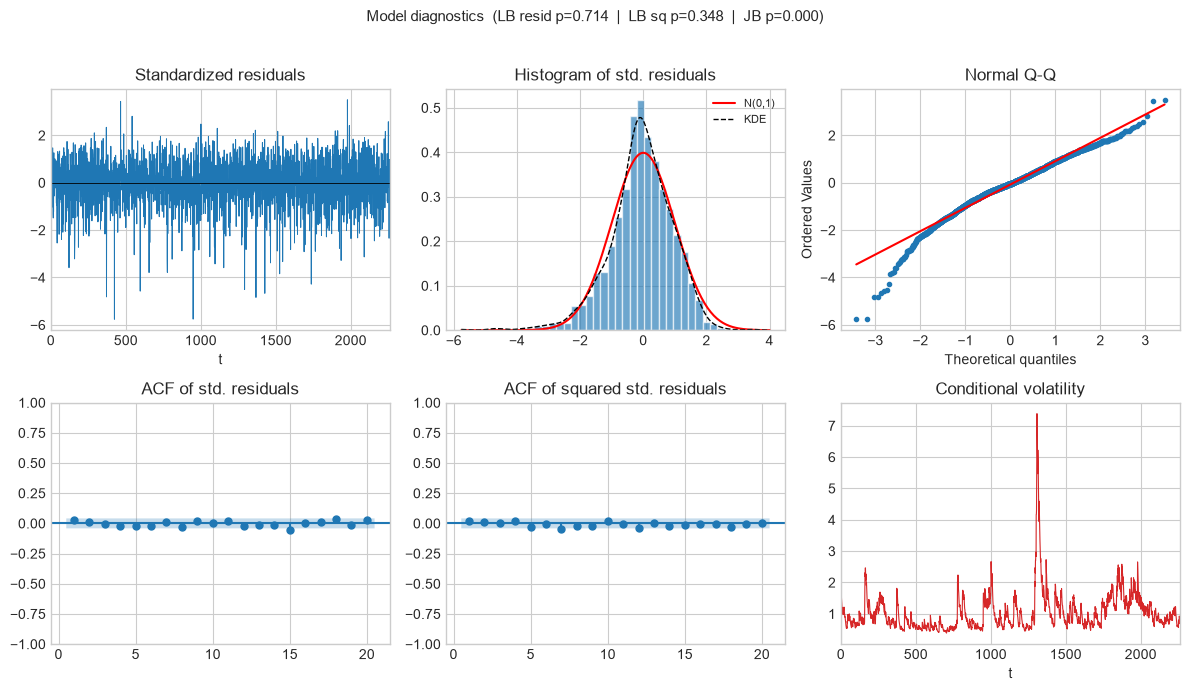

In [22]:
garch_t = arma_garch(
    r,
    mean="AR", ar=1, ma=0, d=0,
    r=1, s=1,
    trend="c",
    dist="t",
).fit(verbose=False)
print(garch_t.summary())
garch_t.plot_diagnostics()
plt.show()

In [23]:
# Information criteria across the pipeline (lower BIC is better)
rows = {
    "AR(1) constant var": mean_ar1,
    "AR(1)–GARCH(1,1) normal": garch_n,
    "AR(1)–GARCH(1,1) Student-t": garch_t,
}
ic2 = pd.DataFrame({
    "AIC": [m.aic for m in rows.values()],
    "BIC": [m.bic for m in rows.values()],
}, index=list(rows.keys()))
print(ic2.round(2))
print()
print("BIC improvement: constant var → GARCH-n:", round(mean_ar1.bic - garch_n.bic, 1))
print("BIC improvement: GARCH-n → GARCH-t:", round(garch_n.bic - garch_t.bic, 1))

                                AIC      BIC
AR(1) constant var          7138.44  7155.61
AR(1)–GARCH(1,1) normal     6028.15  6056.77
AR(1)–GARCH(1,1) Student-t  5911.73  5946.08

BIC improvement: constant var → GARCH-n: 1098.8
BIC improvement: GARCH-n → GARCH-t: 110.7


### Model comparison

On this sample the ranking is almost always:

1. **AR(1)–GARCH(1,1)–t** (best BIC/AIC),
2. AR(1)–GARCH(1,1)–normal,
3. AR(1) with constant variance far behind.

So the data ask for **both** volatility clustering **and** heavy tails. The AR(1) mean remains useful but is secondary in likelihood terms once GARCH is allowed.

**What we did *not* do (on purpose):**

- We did not jump to EGARCH/GJR without first establishing GARCH(1,1) — leverage can be a follow-up test (sign bias / GJR) once the baseline is solid.
- We did not treat GARCH as a remedy for non-stationarity — returns were already I(0).
- We did not select dozens of mean lags to soak up ARCH effects.


## 7. Takeaways

1. **Returns are I(0)** — sequential ADF + KPSS justify ARMA/GARCH in levels of returns (`d = 0`).
2. **Constant-variance AR(1)** is a disciplined mean baseline: weak AR, residuals still highly non-normal and heteroskedastic.
3. **GARCH(1,1)** absorbs clustering; likelihood and residual-square diagnostics improve sharply.
4. **Student-t** addresses fat tails that Gaussian GARCH leaves behind; BIC selects it over normal innovations.
5. The pipeline is intentional: **stationarity → mean → variance → tails**, each step motivated by the failure of the previous specification.

```python
from makystats import adf_sequential, arma, arma_garch
print(adf_sequential(r).summary())
print(arma(r, mean="AR", ar=1, trend="c").fit().summary())
print(arma_garch(r, mean="AR", ar=1, r=1, s=1, dist="t").fit().summary())
```
